# Week 8, task 3: which emissions matter for Southeast Asia + South Asia?

**J** = the 2081–2100 mean of a `pr90` over South Asia (5–35°N, 65–95°E, the RAMIP South Asia box), under ssp245.
We take the gradient of J with respect to all four emulator inputs at once (CO₂, CH₄, SO₂, BC).

In [1]:
import os, glob, time, pickle
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import jax, jax.numpy as jnp
import optax
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.patches import Rectangle
from matplotlib.colors import TwoSlopeNorm

jax.config.update("jax_enable_x64", False)
print(jax.devices())

DATA_ROOT = os.environ.get("DATA_ROOT", os.path.expanduser("~/climatebench/data/"))
OUT = os.environ.get("OUT_DIR", "results")
TAS_PKL = os.environ.get("TAS_EMULATOR", os.path.join(OUT, "emulator.pkl"))   # task 1 emulator
os.makedirs(OUT, exist_ok=True)

TRAIN = ["ssp126", "ssp370", "ssp585", "historical", "hist-GHG", "hist-aer"]
TEST = "ssp245"
N_SO2_PC, N_BC_PC, N_OUT_PC = 5, 5, 20
HIDDEN = (64, 64)
SEEDS = [0, 1, 2, 3, 4]
STEPS, LR, WD = 3000, 1e-3, 1e-4

REGION = {"name": "South and East Asia", "lat": (5, 55), "lon": (65, 135)}
J_START, J_END = 2081, 2100

[CpuDevice(id=0)]


## 1. Data (same loader as task 1, plus precipitation in mm/day)

In [2]:
def find(name):
    hits = glob.glob(os.path.join(DATA_ROOT, "**", name), recursive=True)
    if not hits:
        raise FileNotFoundError(f"{name} not found under {DATA_ROOT}")
    return hits[0]

def load(scenario):
    X = xr.open_dataset(find(f"inputs_{scenario}.nc"))
    Y = xr.open_dataset(find(f"outputs_{scenario}.nc"))
    if "member" in Y.dims:
        Y = Y.mean("member")
    years = np.intersect1d(X.time.values, Y.time.values)
    X, Y = X.sel(time=years), Y.sel(time=years)
    d = {"years": years,
         "co2": X["CO2"].values.astype(np.float32),
         "ch4": X["CH4"].values.astype(np.float32),
         "so2": X["SO2"].transpose("time", ...).values.astype(np.float32),
         "bc":  X["BC"].transpose("time", ...).values.astype(np.float32),
         "tas": Y["tas"].transpose("time", ...).values.astype(np.float32),
         "pr":  (Y["pr"].transpose("time", ...) * 86400).values.astype(np.float32),   # mm/day
         "lat": Y["lat"].values, "lon": Y["lon"].values}
    d["units"] = {k: X[v].attrs.get("units", "?") for k, v in [("co2", "CO2"), ("ch4", "CH4"), ("so2", "SO2"), ("bc", "BC")]}
    return d

data = {}
for s in TRAIN + [TEST]:
    try:
        data[s] = load(s)
        print(f"{s:11s} {data[s]['years'][0]}-{data[s]['years'][-1]}")
    except FileNotFoundError as e:
        print("skipping:", e)
TRAIN = [s for s in TRAIN if s in data]
d = data[TEST]
print("input units:", d["units"])

lat, lon = d["lat"], d["lon"]
NLAT, NLON = len(lat), len(lon)
lat2d = np.repeat(lat[:, None], NLON, axis=1)
lon2d = np.repeat((lon % 360)[None, :], NLAT, axis=0)

area_w = np.cos(np.deg2rad(lat2d)); area_w = jnp.asarray(area_w / area_w.mean(), dtype=jnp.float32)

in_box = ((lat2d >= REGION["lat"][0]) & (lat2d <= REGION["lat"][1]) &
          (lon2d >= REGION["lon"][0]) & (lon2d <= REGION["lon"][1]))
region_w = np.where(in_box, np.cos(np.deg2rad(lat2d)), 0.0)
region_w = jnp.asarray(region_w / region_w.sum(), dtype=jnp.float32)      # sums to 1 over the box
print("grid cells in the region box:", int(in_box.sum()))

years = d["years"]
window = ((years >= J_START) & (years <= J_END)).astype(np.float32)
window = jnp.asarray(window / window.sum())                                  # averages over 2081-2100

# grid-cell area, to turn "per kg m-2 s-1" gradients into "per Tg/yr emitted from that cell"
R = 6.371e6
dlat, dlon = np.deg2rad(abs(lat[1] - lat[0])), np.deg2rad(abs(lon[1] - lon[0]))
cell_area = R**2 * dlat * dlon * np.cos(np.deg2rad(lat2d))                  # m²
KGS_PER_TGYR = 1e9 / (365.25 * 86400)                                        # 1 Tg/yr in kg/s

ssp126      2015-2100


ssp370      2015-2100


ssp585      2015-2100


historical  1850-2014


hist-GHG    1850-2014


hist-aer    1850-2014


ssp245      2015-2100
input units: {'co2': '?', 'ch4': '?', 'so2': '?', 'bc': '?'}
grid cells in the region box: 754


## 2. Emulator code (same structure as week 7 for any target variable)
- 12 → 64 → 64 → 20, with `tanh` activations.
- direct linear connection from inputs to outputs: 12 → 20 to mirror how a lot of NorESM’s temperature response was close to linear

In [3]:
def stack(key):
    return np.concatenate([data[s][key] for s in TRAIN], axis=0)

def pca(maps, k):
    A = maps.reshape(len(maps), -1)
    mean = A.mean(0)
    _, svals, Vt = np.linalg.svd(A - mean, full_matrices=False)
    return mean.astype(np.float32), Vt[:k].astype(np.float32), (svals[:k]**2).sum() / (svals**2).sum()

def features(co2, ch4, so2, bc, pre):
    T = co2.shape[0]
    so2_f = (so2.reshape(T, -1) - pre["so2_mean"]) @ pre["so2_pcs"].T
    bc_f  = (bc.reshape(T, -1)  - pre["bc_mean"])  @ pre["bc_pcs"].T
    return jnp.concatenate([co2[:, None], ch4[:, None], so2_f, bc_f], axis=1)

def make_pre(target):
    pre = {}
    pre["so2_mean"], pre["so2_pcs"], ev1 = pca(stack("so2"), N_SO2_PC)
    pre["bc_mean"],  pre["bc_pcs"],  ev2 = pca(stack("bc"),  N_BC_PC)
    pre["out_mean"], pre["out_pcs"], ev3 = pca(stack(target), N_OUT_PC)
    Y = stack(target).reshape(-1, NLAT * NLON)
    pre["c_std"] = ((Y - pre["out_mean"]) @ pre["out_pcs"].T).std(0) + 1e-8
    pre = {k: jnp.asarray(v) for k, v in pre.items()}
    F = np.concatenate([np.asarray(features(*(jnp.asarray(data[s][k]) for k in ["co2", "ch4", "so2", "bc"]), pre))
                        for s in TRAIN])
    pre["f_mean"], pre["f_std"] = jnp.asarray(F.mean(0)), jnp.asarray(F.std(0) + 1e-8)
    print(f"{target}: SO2 PCs {ev1:.1%}, BC PCs {ev2:.1%}, {N_OUT_PC} output PCs explain {ev3:.1%}")
    return pre

def init_mlp(key, sizes):
    params = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        key, sub = jax.random.split(key)
        params.append({"W": jax.random.normal(sub, (n_in, n_out)) * jnp.sqrt(1.0 / n_in), "b": jnp.zeros(n_out)})
    params.append({"W": jnp.zeros((sizes[0], sizes[-1])), "b": jnp.zeros(sizes[-1])})   # linear shortcut
    return params

def mlp(params, x):
    *layers, skip = params
    h = x
    for layer in layers[:-1]:
        h = jnp.tanh(h @ layer["W"] + layer["b"])
    return h @ layers[-1]["W"] + layers[-1]["b"] + x @ skip["W"] + skip["b"]

def predict(params, co2, ch4, so2, bc, pre):
    x = (features(co2, ch4, so2, bc, pre) - pre["f_mean"]) / pre["f_std"]
    coeffs = mlp(params, x) * pre["c_std"]
    return (pre["out_mean"] + coeffs @ pre["out_pcs"]).reshape(co2.shape[0], NLAT, NLON)

def train(target):
    pre = make_pre(target)
    Xtr = [jnp.asarray(stack(k)) for k in ["co2", "ch4", "so2", "bc"]]
    Ytr = jnp.asarray(stack(target))
    loss_fn = lambda p: jnp.mean(area_w * (predict(p, *Xtr, pre) - Ytr) ** 2)
    opt = optax.adamw(LR, weight_decay=WD)

    @jax.jit
    def step(p, s):
        loss, g = jax.value_and_grad(loss_fn)(p)
        u, s = opt.update(g, s, p)
        return optax.apply_updates(p, u), s, loss

    sizes = [int(pre["f_mean"].shape[0]), *HIDDEN, N_OUT_PC]
    trained = []
    for seed in SEEDS:
        p = init_mlp(jax.random.key(seed), sizes); s = opt.init(p)
        for _ in range(STEPS):
            p, s, loss = step(p, s)
        trained.append(p)
        print(f"  {target} seed {seed}: final train loss {float(loss):.4f}")
    stacked = jax.tree_util.tree_map(lambda *a: jnp.stack(a), *trained)
    return stacked, pre

def save_emulator(path, stacked, pre):
    with open(path, "wb") as f:
        pickle.dump(jax.device_get({"params": stacked, "pre": pre, "nlat": NLAT, "nlon": NLON, "lat": lat, "lon": lon}), f)

def load_emulator(path):
    with open(path, "rb") as f:
        b = pickle.load(f)
    pre = {k: jnp.asarray(v) for k, v in b["pre"].items()}
    if "tas_mean" in pre:                              # task 1 naming
        pre["out_mean"], pre["out_pcs"] = pre.pop("tas_mean"), pre.pop("tas_pcs")
    return jax.tree_util.tree_map(jnp.asarray, b["params"]), pre

def make_emulate(stacked, pre):
    @jax.jit
    def emulate(co2, ch4, so2, bc):
        return jax.vmap(lambda p: predict(p, co2, ch4, so2, bc, pre))(stacked).mean(0)
    return emulate

def seed_params(stacked, i):
    return jax.tree_util.tree_map(lambda a: a[i], stacked)

## 3. Gradient analysis

In [4]:
ARGS = [jnp.asarray(d[k]) for k in ["co2", "ch4", "so2", "bc"]]

def make_J(field_fn):
    """J = 2081-2100 mean over the region of field_fn(co2, ch4, so2, bc) -> (T, lat, lon)."""
    def J(co2, ch4, so2, bc):
        regional = (field_fn(co2, ch4, so2, bc) * region_w).sum((-2, -1))   # (T,)
        return (regional * window).sum()
    return J

def analyze(var, stacked, pre, unit):
    emulate = make_emulate(stacked, pre)
    J = make_J(emulate)
    J0 = float(J(*ARGS))
    g_co2, g_ch4, g_so2, g_bc = jax.grad(J, argnums=(0, 1, 2, 3))(*ARGS)
    g_co2, g_ch4, g_so2, g_bc = (np.asarray(g) for g in (g_co2, g_ch4, g_so2, g_bc))

    # CO2 input is CUMULATIVE: one extra unit emitted in year t raises the total in every year >= t
    g_co2_annual = np.cumsum(g_co2[::-1])[::-1]

    polar = np.abs(lat2d) > 80                                     # tiny cells near the poles blow up "per Tg" values
    so2_map = np.where(polar, np.nan, g_so2.sum(0) / cell_area * KGS_PER_TGYR)   # per Tg SO2/yr from that cell
    bc_map  = np.where(polar, np.nan, g_bc.sum(0)  / cell_area * KGS_PER_TGYR)
    contrib = (g_so2 * np.asarray(ARGS[2])).sum(0)                 # linearized contribution of ssp245 SO2, per cell
    outside = float(np.abs(contrib[~in_box]).sum() / np.abs(contrib).sum())

    truth = (d[var] * np.asarray(region_w)).sum((-2, -1))
    pred  = (np.asarray(emulate(*ARGS)) * np.asarray(region_w)).sum((-2, -1))
    print(f"{var}: J (emulator) = {J0:.3f} {unit} | J (NorESM2) = {float((truth * np.asarray(window)).sum()):.3f} {unit}")
    print(f"  share of the |SO2 contribution| from outside the {REGION['name']} box: {outside:.0%}")
    return dict(var=var, unit=unit, J=J0, g_co2=g_co2, g_co2_annual=g_co2_annual, g_ch4=g_ch4,
                so2_map=so2_map, bc_map=bc_map, contrib=contrib, outside=outside, truth=truth, pred=pred)

def box_outline(ax):
    (a, b), (c, e) = REGION["lat"], REGION["lon"]
    ax.plot([c, e, e, c, c], [a, a, b, b, a], "k-", lw=1.2)

def plot_results(r):
    fig, ax = plt.subplots(2, 2, figsize=(15, 8), constrained_layout=True)
    ax[0, 0].plot(years, r["truth"], label="NorESM2"); ax[0, 0].plot(years, r["pred"], label="emulator")
    ax[0, 0].axvspan(J_START, J_END, color="orange", alpha=0.2, label="J window")
    ax[0, 0].set(title=f"{REGION['name']} mean {r['var']}", ylabel=r["unit"]); ax[0, 0].legend()

    ax[0, 1].plot(years, r["g_co2_annual"] * 1000, label=f"CO2: per 1000 Gt emitted in year t")
    ax2 = ax[0, 1].twinx()
    ax2.plot(years, r["g_ch4"], color="C1", label="CH4: per unit emitted in year t")
    ax[0, 1].set(title=f"dJ/d(emissions in year t), {r['var']}", xlabel="year of emission",
                 ylabel=f"{r['unit']} per 1000 GtCO2")
    ax2.set_ylabel(f"{r['unit']} per unit CH4 ({d['units']['ch4']})")
    ax[0, 1].legend(loc="upper left"); ax2.legend(loc="center left")

    for a, key, title in [(ax[1, 0], "so2_map", "Sensitivity to SO2 emitted at each cell"),
                          (ax[1, 1], "contrib", "Contribution of ssp245 SO2 (gradient x emissions)")]:
        f = r[key]; lim = np.nanpercentile(np.abs(f), 99.5) or 1
        m = a.pcolormesh(lon % 360 if np.all(np.diff(lon % 360) > 0) else lon, lat, f, cmap="RdBu_r", vmin=-lim, vmax=lim)
        box_outline(a); a.set_title(title); a.set_xlabel("lon"); a.set_ylabel("lat")
        plt.colorbar(m, ax=a, label=(f"{r['unit']} per Tg SO2/yr" if key == "so2_map" else r["unit"]))
    fig.suptitle(f"J = {J_START}-{J_END} mean {r['var']} over {REGION['name']}  (J = {r['J']:.3f} {r['unit']})")
    fig.savefig(os.path.join(OUT, f"task3_{r['var']}_gradients.png"), dpi=130)
    plt.show()

loaded task 1 emulator: /data/week8/results/emulator.pkl


tas: J (emulator) = 2.612 K | J (NorESM2) = 2.563 K
  share of the |SO2 contribution| from outside the South and East Asia box: 38%


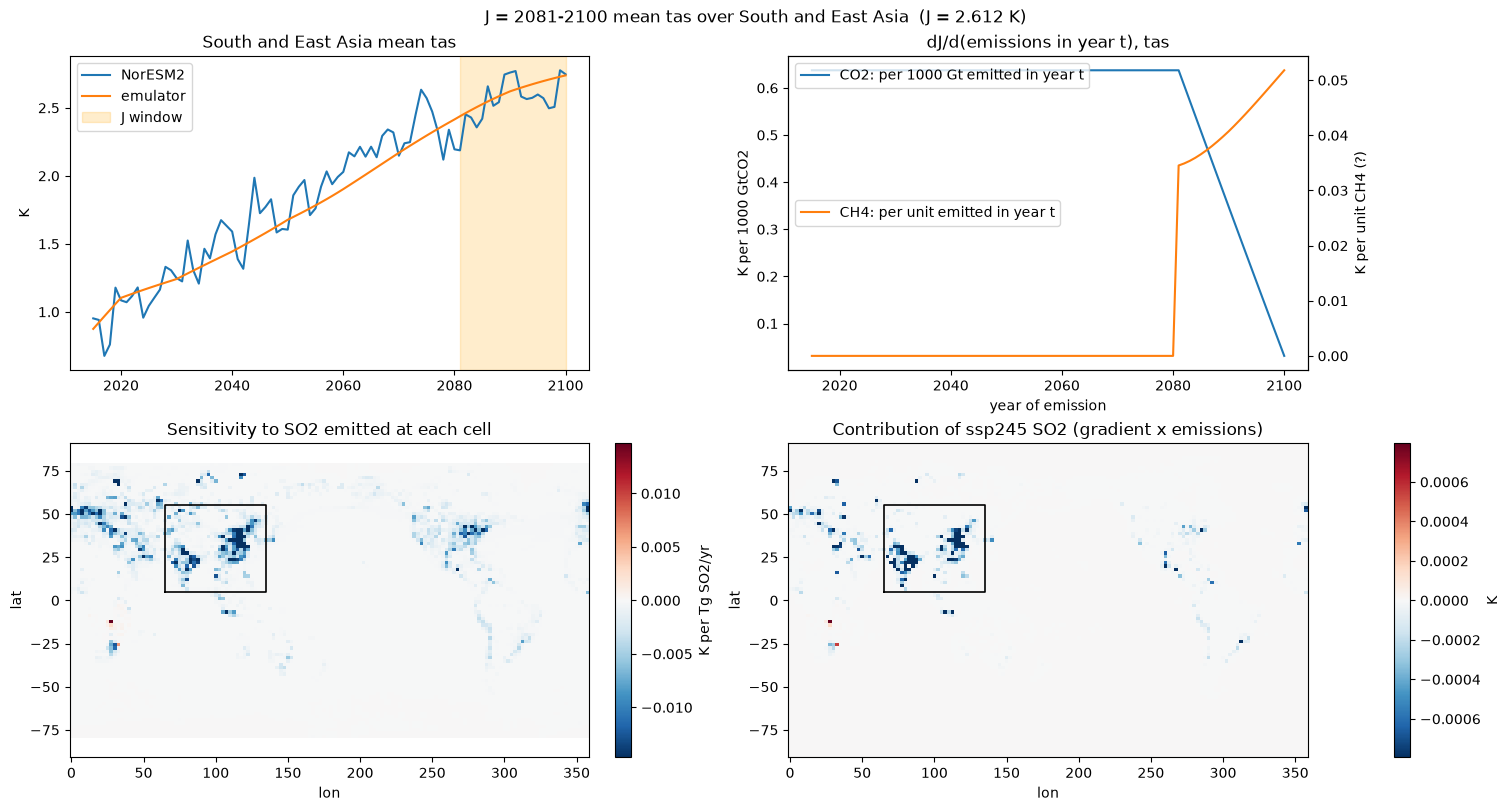

In [5]:
if os.path.exists(TAS_PKL):
    tas_params, tas_pre = load_emulator(TAS_PKL)
    print("loaded task 1 emulator:", TAS_PKL)
else:
    print("no task 1 emulator found, training one")
    tas_params, tas_pre = train("tas")
    save_emulator(os.path.join(OUT, "emulator.pkl"), tas_params, tas_pre)

res_tas = analyze("tas", tas_params, tas_pre, "K")
plot_results(res_tas)

## Precipitation over Southeast + South Asia Analysis

pr: SO2 PCs 94.9%, BC PCs 98.1%, 20 output PCs explain 74.1%


  pr seed 0: final train loss 0.3662


  pr seed 1: final train loss 0.3574


  pr seed 2: final train loss 0.3502


  pr seed 3: final train loss 0.3681


  pr seed 4: final train loss 0.3642


pr emulator on ssp245: {'spatial': 5.46, 'global': 0.176, 'total': 6.341}


pr: J (emulator) = 0.155 mm/day | J (NorESM2) = 0.133 mm/day
  share of the |SO2 contribution| from outside the South and East Asia box: 60%


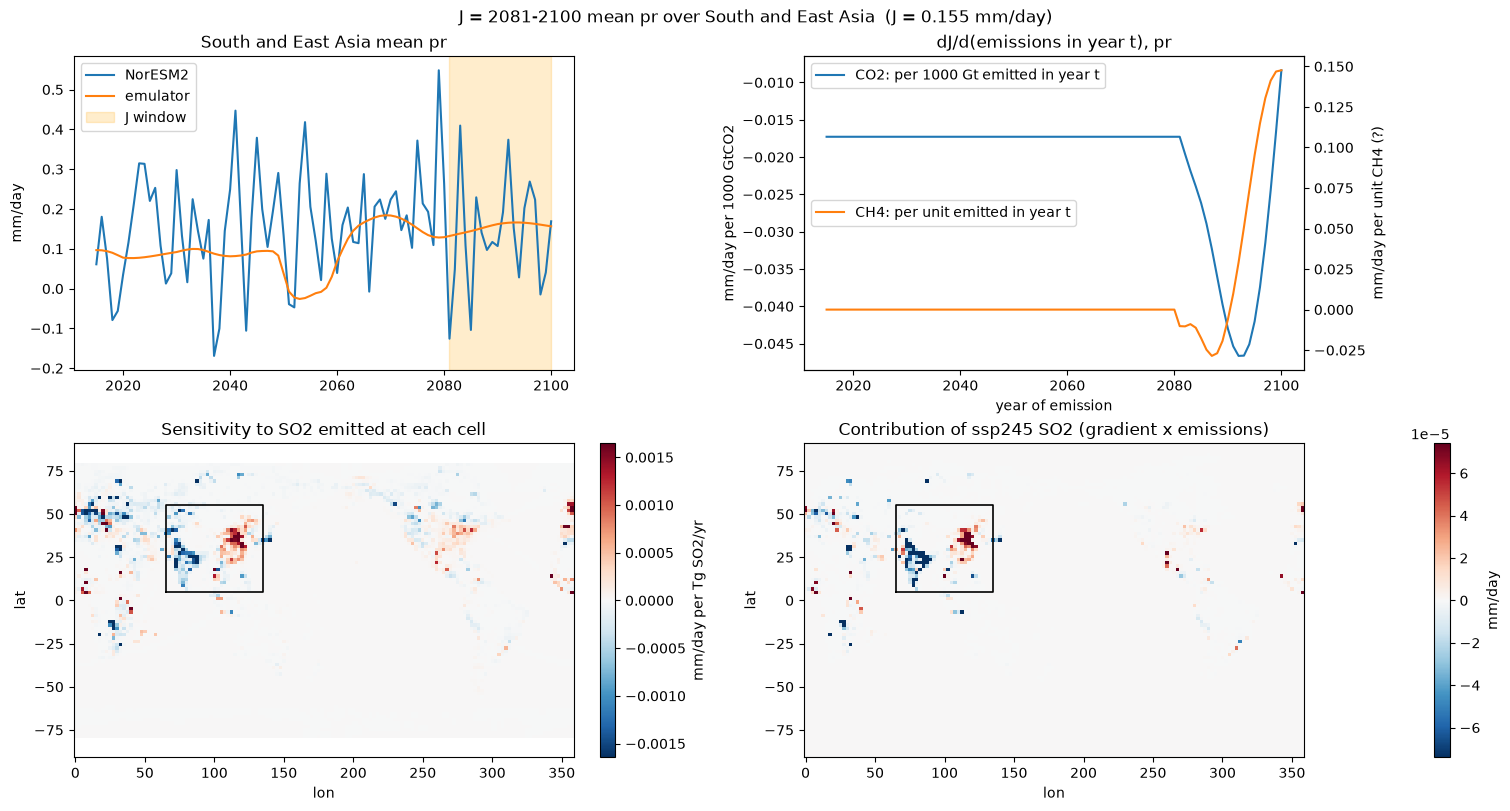

In [6]:
pr_params, pr_pre = train("pr")
save_emulator(os.path.join(OUT, "emulator_pr.pkl"), pr_params, pr_pre)

# quick skill check on ssp245 (same NRMSE as week 3)
def gmean(x): return (x * area_w).mean((-2, -1))
def nrmse(truth, pred, start=2080, end=2100):
    sel = (years >= start) & (years <= end)
    t, p = jnp.asarray(truth[sel]), jnp.asarray(pred[sel])
    norm = abs(float(gmean(t.mean(0))))
    sp = float(jnp.sqrt(gmean((t.mean(0) - p.mean(0)) ** 2))) / norm
    gl = float(jnp.sqrt(jnp.mean((gmean(t) - gmean(p)) ** 2))) / norm
    return {"spatial": sp, "global": gl, "total": sp + 5 * gl}

print("pr emulator on ssp245:", {k: round(v, 3) for k, v in nrmse(d["pr"], make_emulate(pr_params, pr_pre)(*ARGS)).items()})

res_pr = analyze("pr", pr_params, pr_pre, "mm/day")
plot_results(res_pr)

/opt/conda/lib/python3.13/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


/opt/conda/lib/python3.13/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_boundary_lines_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


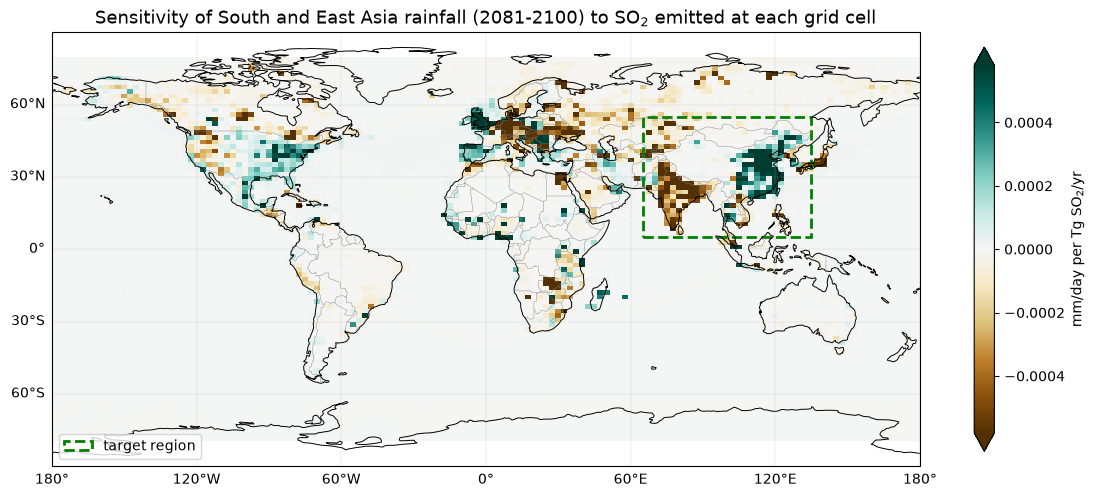

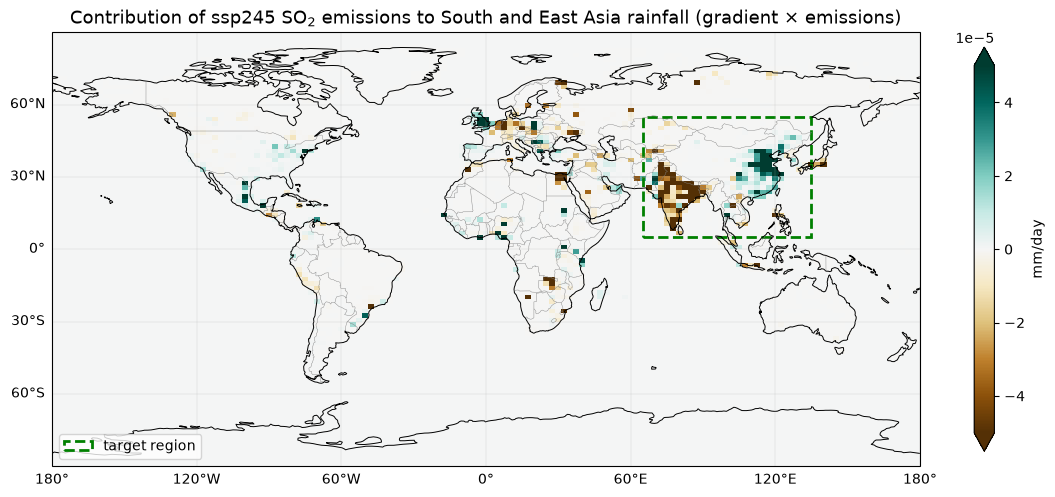

In [7]:
def plot_map(field, title, cbar_label, cmap="RdBu_r", pct=98, fname=None):
    """Big map of a (lat, lon) field with coastlines, borders and the region box."""
    f = np.asarray(field, dtype=float)
    lon180 = ((lon + 180) % 360) - 180
    order = np.argsort(lon180)
    lon_s, f = lon180[order], f[:, order]

    nz = np.abs(f[np.isfinite(f) & (f != 0)])
    lim = np.percentile(nz, pct) if nz.size else 1.0 

    fig = plt.figure(figsize=(14, 7))
    ax = plt.axes(projection=ccrs.PlateCarree())
    m = ax.pcolormesh(lon_s, lat, f, cmap=cmap, norm=TwoSlopeNorm(0, -lim, lim),
                      transform=ccrs.PlateCarree(), shading="auto")
    ax.coastlines(linewidth=0.7)
    ax.add_feature(cfeature.BORDERS, linewidth=0.3, edgecolor="gray")
    ax.set_global()
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, alpha=0.5)
    gl.top_labels = gl.right_labels = False

    (la0, la1), (lo0, lo1) = REGION["lat"], REGION["lon"]
    ax.add_patch(Rectangle((lo0, la0), lo1 - lo0, la1 - la0, fill=False, edgecolor="green",
                           linestyle="--", linewidth=2, transform=ccrs.PlateCarree(), label="target region"))
    ax.legend(loc="lower left")

    plt.colorbar(m, ax=ax, orientation="vertical", shrink=0.75, extend="both", label=cbar_label)
    ax.set_title(title, fontsize=13)
    if fname:
        fig.savefig(os.path.join(OUT, fname), dpi=200, bbox_inches="tight")
    plt.show()

# precipitation: brown = less rain, green = more rain
plot_map(res_pr["so2_map"],
         f"Sensitivity of {REGION['name']} rainfall ({J_START}-{J_END}) to SO$_2$ emitted at each grid cell",
         "mm/day per Tg SO$_2$/yr", cmap="BrBG", fname="pr_so2_sensitivity_map.png")
plot_map(res_pr["contrib"],
         f"Contribution of ssp245 SO$_2$ emissions to {REGION['name']} rainfall (gradient × emissions)",
         "mm/day", cmap="BrBG", fname="pr_so2_contribution_map.png")